# Development image registartion with simpleElastix

## TODO:

- [x] load data
- [x] test registration
- [x] mask data before registration (black background from rotation)
- [x] obtain suitable and safe masks with the most rotated sample --> should be safe
    - better sample specific mask

In [2]:
#modules
import xarray as xr
import json
import os
import socket
host = socket.gethostname()
import matplotlib.pyplot as plt
import SimpleITK as sitk
import numpy as np

# paths
if host == 'mpc2959.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    # toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppath = '/mnt/SSD/fische_r/COELY'
    
path_01_4D = os.path.join(toppath, '01_rotated_3p1D')
registration_mask_path = os.path.join(gitpath, 'processing', 'masking_for_registration.json')

In [3]:
mask_dimension = json.load(open(registration_mask_path, 'r'))

In [281]:
# jsonpath = os.path.join(gitpath, 'processing', 'masking_for_registration.json')
# with open(jsonpath, "w") as outfile:
    # json.dump(mask_dimension, outfile,indent = 4)
      

## Test: load two operando scans and register

In [4]:
sample = '5II'
file = '01_'+sample+'_rotated_3p1D.nc'
imagepath = os.path.join(path_01_4D, file)
data = xr.open_dataset(imagepath)
images = [im for im in data.keys() if im[3:7] == 'imag']
images.sort()

In [5]:
image1 = images[5]
image2 = images[0]

In [6]:
im1 = data[image1].data
im2 = data[image2].data

In [8]:
mask = np.zeros(im1.shape, dtype=np.uint8)
a,b,c,d,e,f = mask_dimension[sample]
mask[a:b,c:d,e:f] = 1 #

In [9]:
data.close()

In [10]:
# a = 30
# b = -30
# c = 30
# d = -10
# e = 30
# f = -30

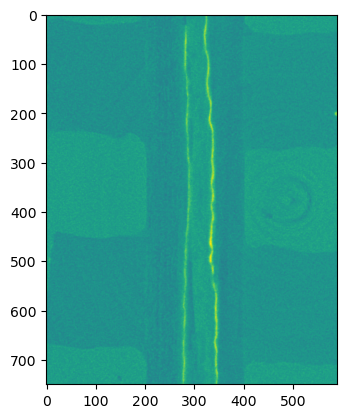

In [11]:
plt.imshow(im1[a:b,c:d,e]) #int(im1.shape[2]/2)

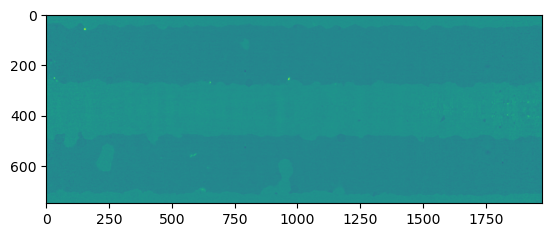

In [12]:
plt.imshow(im1[a:b,d,e:f]) #int(im1.shape[1]/2)

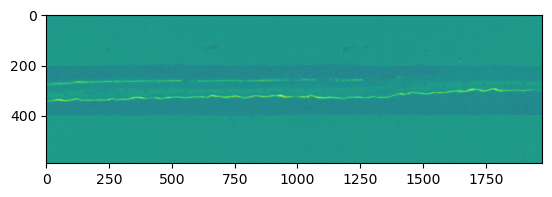

In [13]:
plt.imshow(im1[b,c:d,e:f]) #int(im1.shape[1]/2)

In [15]:
#if ok, save mask dimension
# mask_dimension[sample] = [a, b, c, d, e, f]

In [16]:
# copied from Salvo's and Mayank's code
# TODO: adapat for own purpose, i.e. masking, parallelization, affine registration, transformation matrix
def register_images_general(im_fixed, im_tomove, parameter_map, verbose=False, im_mask=None):

    r"""
    General registration for 2D or 3D images
    This function allows control over the parameter map
    
         
    Parameters
    ----------     
    im_fixed : numpy.ndarray
        Fixed image
    im_tomove: numpy.ndarray
        Image to register (to im_fixed)
    parameter_map: sitk.ParameterMap
        Parameters map object as obtained from sitk.GetParameterMap
    verbose : bool, optional (default=False)
        Enable/Disable log to console 
    im_mask : numpy.ndarray (default=None)
        Mask for sampling points (required). 
        im_mask has same dimensions as im_fixed 
        The mask ndarray has 1 and 0. 1 values denote the area where
        points for the registration are sampled.    
    Returns
    -------
    im_aligned : numpy.ndarray
        Aligned image having same dimensions of im_tomove
                 
    Notes
    -----
    To have further info on parameter maps, go to:
    https://simpleelastix.readthedocs.io/ParameterMaps.html
    For more details on the different parameters, download:
    https://elastix.lumc.nl/download/elastix_manual_v4.8.pdf
    """


    itk_image_fixed = sitk.GetImageFromArray(im_fixed)
    itk_image_tomove = sitk.GetImageFromArray(im_tomove)
           
    elastixImageFilter = sitk.ElastixImageFilter()
    elastixImageFilter.SetFixedImage(itk_image_fixed)
    elastixImageFilter.SetMovingImage(itk_image_tomove)
    elastixImageFilter.SetParameterMap(parameter_map)
    
    if im_mask is not None:
        itk_image_mask = sitk.GetImageFromArray(im_mask)
        # Casting type just in case
        itk_image_mask = sitk.Cast(itk_image_mask, sitk.sitkUInt8)
        elastixImageFilter.SetFixedMask(itk_image_mask)
    
    # Disable/enable logging 
    elastixImageFilter.SetLogToConsole(verbose)
    elastixImageFilter.Execute()

    im_aligned = elastixImageFilter.GetResultImage()
    # Transfor again to numpy
    im_aligned = sitk.GetArrayFromImage(im_aligned)
    return im_aligned

In [17]:
#TODO rigid and affine registration
# TODO: check doc of simpleITK and 3Dslcier to reproduce the settings of Jeremy
##### Parameters for the registration   ################
parameterMap = sitk.GetDefaultParameterMap("rigid") #get default settins for rigid registration

# modify some parameters
parameterMap["FixedImagePyramid"] = ["FixedShrinkingImagePyramid"]
parameterMap["MovingImagePyramid"] = ["MovingShrinkingImagePyramid"]
parameterMap["NumberOfResolutions"] = ["2"]
parameterMap["MaximumNumberOfIterations"] = ["1500"]
parameterMap["AutomaticTransformInitialization"] = ["true"]
parameterMap["AutomaticScalesEstimation"] = ["true"]
parameterMap["NewSamplesEveryIteration"] = ["true"]
parameterMap["NewSamplesEveryIteration"] = ["true"]
parameterMap["Interpolator"] = ["BSplineInterpolator"]
parameterMap["NumberOfSamplesForExactGradient"] = ["10000"]
parameterMap["NumberOfSpatialSamples"] = ["10000"]

In [18]:
im2_aligned = register_images_general(im1,im2, parameterMap, im_mask=mask)

(array([2.70370e+05, 3.88330e+04, 6.78900e+03, 2.45000e+03, 1.85500e+03,
        1.43200e+03, 1.01600e+03, 7.94000e+02, 4.30000e+02, 1.75000e+02,
        7.20000e+01, 2.90000e+01, 7.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 3.00000e+00, 1.90000e+01, 3.60000e+01,
        1.42000e+02, 3.69000e+02, 6.95000e+02, 8.87000e+02, 1.09400e+03,
        1.56000e+03, 2.36400e+03, 4.03300e+03, 1.55900e+04, 6.70840e+04,
        1.51372e+05, 0.00000e+00, 0.00000e+00, 0.00

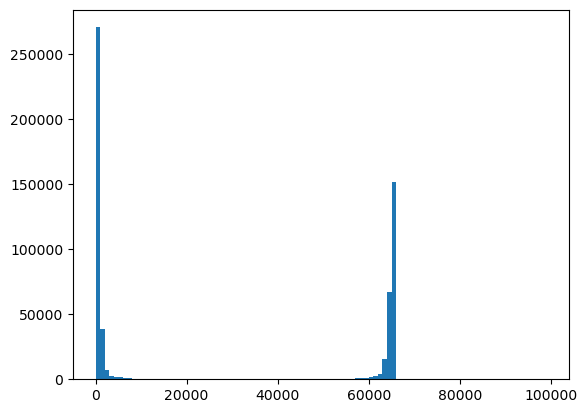

In [19]:
plt.hist(np.abs(im1[:,:,500] -im2[:,:,500]).flatten(), bins=np.arange(0,100000,1000))
# plt.hist(np.abs(im1[:,:,500] -im2_aligned[:,:,500]).flatten())

(array([20743.,  4862.,  4699.,  4688.,  4902.,  4801.,  4706.,  4779.,
         4842.,  4690.,  4780.,  4721.,  4646.,  4760.,  4686.,  4695.,
         4657.,  4701.,  4575.]),
 array([ 0.,  5., 10., 15., 20., 25., 30., 35., 40., 45., 50., 55., 60.,
        65., 70., 75., 80., 85., 90., 95.]),
 <BarContainer object of 19 artists>)

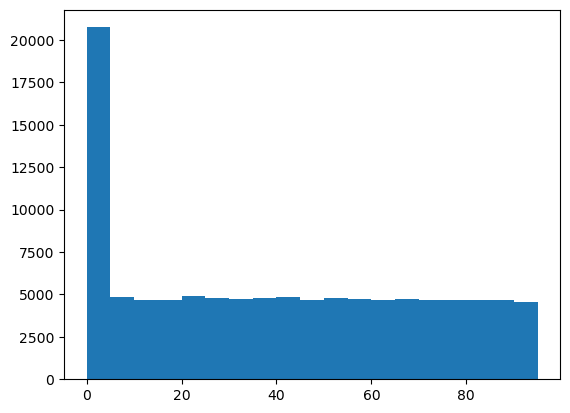

In [20]:
plt.hist(np.abs(im1[:,:,500] -im2_aligned[:,:,500]).flatten(), bins=np.arange(0,100,5))

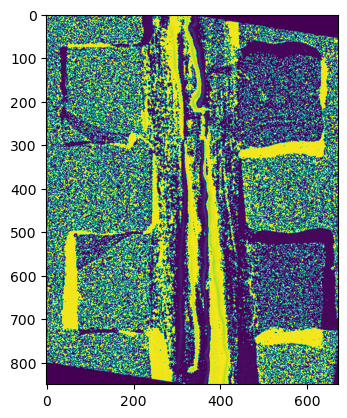

In [21]:
plt.imshow(np.abs(im1[:,:,500] -im2[:,:,500]))

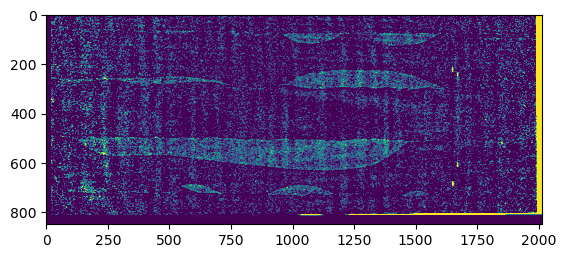

In [28]:
plt.imshow(im1[:,100,:] -im2_aligned[:,100,:], vmin=0,vmax=1000)

(array([5.13159e+05, 2.03540e+04, 6.54300e+03, 3.68100e+03, 1.61700e+03,
        6.18900e+03, 1.78130e+04, 9.70000e+01, 1.80000e+01, 2.90000e+01]),
 array([    0.        ,  2050.60009766,  4101.20019531,  6151.79980469,
         8202.40039062, 10253.        , 12303.59960938, 14354.20019531,
        16404.80078125, 18455.40039062, 20506.        ]),
 <BarContainer object of 10 artists>)

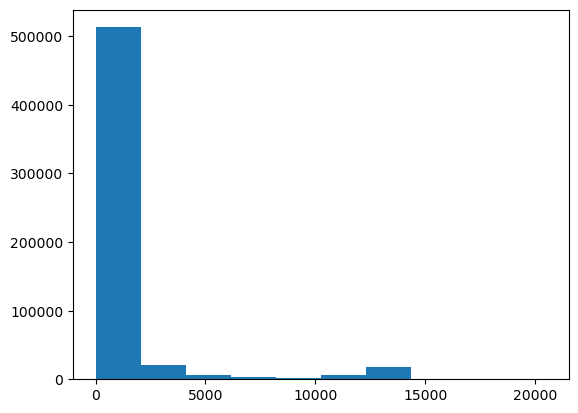

In [23]:
plt.hist(np.abs(im2[:,:,500] -im2_aligned[:,:,500]).flatten())